In [1]:
import h5py
import pyvista as pv
import numpy as np 
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt 
import sys,os,glob,re
from IPython.display import Image as ipImage
from PIL import Image
import imageio
from scipy.ndimage import zoom
from skimage.transform import resize

In [4]:
def fetchFiles(path,keyword_in=None,keyword_out=None,sort=True):
    """
    Fetches files from a given path, optionally filtering them by inclusion or exclusion keywords,
    and sorts them in natural order if specified.
    
    Parameters:
    - path: The directory path where to search for files.
    - keyword_in: Optional list of keywords to include files. Only files containing any of these keywords will be included.
    - keyword_out: Optional list of keywords to exclude files. Any file containing any of these keywords will be excluded.
    - sort: Boolean indicating whether the returned file list should be sorted in natural order. Defaults to True.
    
    Returns:
    - List of file paths, filtered and sorted according to the specified criteria.
    """

    # Helper function to convert text to integers if possible,
    # which helps in sorting files naturally.
    def atoi(text):
        return int(text) if text.isdigit() else text

    # Split file names into parts that are integers or non-integers,
    # and convert integers to actual integers for natural sorting.
    def natural_keys(text):
        return [ atoi(c) for c in re.split('(\d+)',text) ]

    # Use glob to find all files matching the path pattern.
    files=glob.glob(path)

    # If inclusion keywords are specified, filter the files to include
    # only those containing any of the inclusion keywords.
    if keyword_in:
        keywordFilter=keyword_in
        files = [sent for sent in files
            if any(word in sent for word in keywordFilter)]

    # If exclusion keywords are specified, filter the files to exclude
    # those containing any of the exclusion keywords.
    if keyword_out:
        keywordFilter=keyword_out
        files = [sent for sent in files
            if not any(word in sent for word in keywordFilter)]

    # If sorting is enabled, sort the files using the natural keys method,
    # which considers numerical values for sorting parts of the file names.
    if sort:
        files.sort(key=natural_keys)
        return files
    else:
        return files

def minmaxnorm(data,axis=(0,1,2),max_=None,min_=None):
    """
    Normalize the input data to a range [0, 1] using min-max scaling.
    
    Parameters:
    - data: The input data to normalize.
    - axis: The axis or axes along which to find the minimum and maximum values.
    - max_: Optional maximum value for scaling. If not provided, it is computed from the data.
    - min_: Optional minimum value for scaling. If not provided, it is computed from the data.
    
    Returns:
    - The normalized data.
    """

    # If a maximum value is provided, use it; otherwise, compute the maximum
    # from the data along the specified axis or axes.
    if max_:
        pass
    else:
        max_ = np.max(data,axis=axis)

    # If a minimum value is provided, use it; otherwise, compute the minimum
    # from the data along the specified axis or axes.
    if min_:
        pass
    else:
        min_ = np.min(data,axis=axis)

    # Perform the min-max normalization and return the normalized data.
    # This scales all values to be within the range [0, 1].
    return (data-min_)*(1/(max_-min_))

In [7]:
# Loop through files matching a pattern (eg. h5 files containing "data_LR_")
# fetched by the fetchFiles function. `volume_index` is the index of each file,
# and `target` is the file path.
base_path = '/Users/jonathan/Documents/applications/superres/output_analysis/'

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_LR_'])):
    # Open the current h5 file in read mode.
    data = h5py.File(target,'r')
    #print shape of data


    # If this is the first file, initialize the data arrays by loading and squeezing
    # single data volumes from the file. `np.newaxis` is used to add a new axis,
    # preparing for concatenation along this axis for subsequent files.
    if volume_index == 0:
        u = np.squeeze(data['u'][...])[...,np.newaxis]
        v = np.squeeze(data['v'][...])[...,np.newaxis]
        w = np.squeeze(data['w'][...])[...,np.newaxis]
        mu = np.squeeze(data['mag_u'][...])[...,np.newaxis]
        mv = np.squeeze(data['mag_v'][...])[...,np.newaxis]
        mw = np.squeeze(data['mag_w'][...])[...,np.newaxis]
    else:
        # For subsequent files, concatenate the new data volumes along the last axis.
        u = np.concatenate((u,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        v = np.concatenate((v,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        w = np.concatenate((w,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        mu = np.concatenate((mu,np.squeeze(data['mag_u'][...])[...,np.newaxis]),axis=-1)
        mv = np.concatenate((mv,np.squeeze(data['mag_v'][...])[...,np.newaxis]),axis=-1)
        mw = np.concatenate((mw,np.squeeze(data['mag_w'][...])[...,np.newaxis]),axis=-1)  
    
    # Store velocity encoding values in a list for further use.
    venc = [data['venc_u'][...],data['venc_v'][...],data['venc_w'][...]]

    # Close the current h5 file to free resources.
    data.close()   

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_upsampled_'])):
    data = h5py.File(target,'r')
    if volume_index == 0:
        # Initialize high-resolution data arrays for the first file.
        us = np.squeeze(data['u'][...])[...,np.newaxis]
        vs = np.squeeze(data['v'][...])[...,np.newaxis]
        ws = np.squeeze(data['w'][...])[...,np.newaxis]
    else:
        # Concatenate new data volumes to the existing arrays for subsequent files.
        us = np.concatenate((us,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        vs = np.concatenate((vs,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        ws = np.concatenate((ws,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        
    # Close the current h5 file to free resources.
    data.close()  

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_HR_'])):
    data = h5py.File(target,'r')
    if volume_index == 0:
        # Initialize high-resolution data arrays for the first file.
        ugt = np.squeeze(data['u'][...])[...,np.newaxis]
        vgt = np.squeeze(data['v'][...])[...,np.newaxis]
        wgt = np.squeeze(data['w'][...])[...,np.newaxis]
        mask = np.squeeze(data['mask'][...])[...,np.newaxis]
    else:
        # Concatenate new data volumes to the existing arrays for subsequent files.
        ugt = np.concatenate((ugt,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        vgt = np.concatenate((vgt,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        wgt = np.concatenate((wgt,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        mask = np.concatenate((mask,np.squeeze(data['mask'][...])[...,np.newaxis]),axis=-1)
        
    # Close the current h5 file to free resources.
    data.close()   

KeyError: "Unable to synchronously open object (object 'mag_u' doesn't exist)"

In [6]:
print("U shape ", us.shape)
print("U ground truth shape ", ugt.shape)
print("Mask shape ", mask.shape)
print("venc shape ", venc)

NameError: name 'us' is not defined

In [ ]:
us = us
vs = vs
ws = ws

ugt = ugt*venc[0]
vgt = vgt*venc[1]
wgt = wgt*venc[2]


In [ ]:
print("max u ", np.max(us))
print("max v ", np.max(vs))
print("max w ", np.max(ws))

print("max u_gt ", np.max(ugt))
print("max v_gt ", np.max(vgt))
print("max w_gt ", np.max(wgt))

max u  2.2175958
max v  0.62352294
max w  1.0285487
max u_gt  5.31
max v_gt  1.738
max w_gt  2.504


In [ ]:
# add a new axis to the data
us = us[np.newaxis,...]
vs = vs[np.newaxis,...]
ws = ws[np.newaxis,...]

ugt = ugt[np.newaxis,...]
vgt = vgt[np.newaxis,...]
wgt = wgt[np.newaxis,...]

In [ ]:
target = np.concatenate((us,vs,ws),axis=0)
target_gt = np.concatenate((ugt,vgt,wgt),axis=0)

In [ ]:
print(np.mean(target_gt))

0.01451


In [ ]:
print(target.shape)

(3, 214, 66, 46, 20)


In [ ]:
# shape is (3,214,66,46,20), compute the norm of the velocity to have a shape (214,66,46,20)


In [ ]:


print("Before resize target shape: ", target.shape)
print("Target ground truth shape: ", target_gt.shape)
#resize like this but for every frame in the dataset separately
resized_target = np.zeros(target_gt.shape)

for i in range(target.shape[4]):
    resized_target[...,i] = resize(target[...,i], target_gt[...,i].shape, order=3, mode='constant', anti_aliasing=True)

print("Resized target shape: ", resized_target.shape, "    Target ground truth shape: ", target_gt.shape)


Before resize target shape:  (3, 214, 66, 46, 20)
Target ground truth shape:  (3, 217, 67, 47, 20)
Resized target shape:  (3, 217, 67, 47, 20)     Target ground truth shape:  (3, 217, 67, 47, 20)


In [ ]:
print(np.mean(target_gt))

0.01451


In [ ]:
binary_mask = np.zeros(mask.shape,dtype=bool)
binary_mask[mask>0.5] = True
binary_mask_non_fluid = np.logical_not(binary_mask)
print("Binary mask shape: ", binary_mask.shape)
resized_target_v = np.sqrt(np.sum(resized_target**2,axis=0))
target_gt_v = np.sqrt(np.sum(target_gt**2,axis=0))
masked_target = resized_target[:,binary_mask]
nf_masked_target = resized_target[:,binary_mask_non_fluid]
masked_target_gt = target_gt[:,binary_mask]
nf_masked_target_gt = target_gt[:,binary_mask_non_fluid]

# apply binary max to each frame of the array resized_target (214,66,46,20) the frame number is the last dimension
masked_velocity = []
masked_velocity_gt = []
masked_target_list = []
masked_target_gt_list = []
for i in range(binary_mask.shape[3]):
    masked_velocity.append(resized_target_v[binary_mask[...,i],i])
    masked_velocity_gt.append(target_gt_v[binary_mask[...,i],i])
    masked_target_list.append(resized_target[:,binary_mask[...,i],i])
    masked_target_gt_list.append(target_gt[:,binary_mask[...,i],i])

print(len(masked_velocity))
print(masked_velocity[0].shape)

Binary mask shape:  (217, 67, 47, 20)


20
(54621,)


In [ ]:
# compute the average velocity magnitude for each frame
average_velocity = []
average_velocity_gt = []
for i in range(len(masked_velocity)):
    average_velocity.append(np.mean(masked_velocity[i]))
    average_velocity_gt.append(np.mean(masked_velocity_gt[i]))

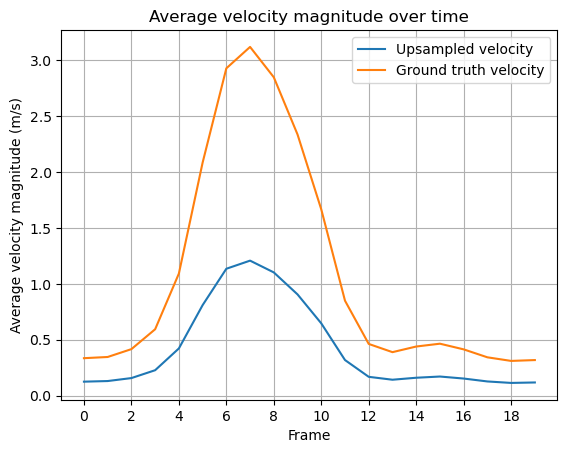

In [ ]:
# plot the average velocity over time

plt.plot(average_velocity, label='Upsampled velocity')
plt.plot(average_velocity_gt, label='Ground truth velocity')
# make the x label unitary range from 0 to 19
plt.xticks(np.arange(0, 20, 2))
plt.xlabel('Frame')
plt.ylabel('Average velocity magnitude (m/s)')
plt.legend()
plt.title('Average velocity magnitude over time')
plt.grid()
plt.show()


In [ ]:
def directional_error(vectors_a, vectors_b):
    # Dot product between pairs of vectors
    dot_product = np.abs(np.einsum('ij,ij->j', vectors_a, vectors_b))

    # Norm (magnitude) of each vector
    norm_a = np.linalg.norm(vectors_a, axis=0) + 1e-7
    norm_b = np.linalg.norm(vectors_b, axis=0) + 1e-7
    return np.mean(1-dot_product/norm_a/norm_b)*100

def vectorial_rmse(vectors_a, vectors_b):
    # Vectorial difference
    diff = np.mean(np.linalg.norm(vectors_a-vectors_b,axis=0)**2)
    #Norm (magnitude) of reference target (here: vectors_b)
    norm = np.mean(np.linalg.norm(vectors_b,axis=0)**2)
    
    return np.sqrt(diff/norm)*100
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

In [ ]:
print(masked_target)

[[-0.00659198  0.0001433   0.01290092 ...  0.06499991  0.06415281
   0.06071373]
 [-0.04386261 -0.00748645 -0.00380885 ... -0.02862091 -0.02587702
  -0.01397146]
 [-0.00320057 -0.00615725 -0.0061895  ...  0.03081803  0.01908193
   0.01696347]]


In [ ]:
print(masked_target_gt)

[[ 1.0185e-02 -3.0632e-03  1.6212e-03 ...  5.8887e-01  6.0742e-01
   6.2451e-01]
 [-1.0596e-01 -3.1261e-03 -8.5526e-03 ... -1.7993e-01 -2.2510e-01
  -2.2473e-01]
 [-3.1982e-02 -5.8222e-04  2.2812e-02 ...  1.1597e-01  1.1694e-01
   1.1932e-01]]


In [ ]:
print("Fluid region:\n")
dir_error = directional_error(masked_target.reshape(3,-1),masked_target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(masked_target.reshape(3,-1),masked_target_gt.reshape(3,-1))
rmse_val = rmse(masked_target,masked_target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Fluid region:

Directional error: 4.86%
Vectorial RMSE: 62.61%
RMSE: 0.592


In [ ]:
print("Fluid + non fluid region:\n")
dir_error = directional_error(resized_target.reshape(3,-1),target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(resized_target.reshape(3,-1),target_gt.reshape(3,-1))
rmse_val = rmse(resized_target,target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Fluid + non fluid region:

Directional error: 92.18%
Vectorial RMSE: 62.93%
RMSE: 0.171


In [ ]:
print("Non fluid region:\n")
dir_error = directional_error(nf_masked_target.reshape(3,-1),nf_masked_target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(nf_masked_target.reshape(3,-1),nf_masked_target_gt.reshape(3,-1))
rmse_val = rmse(nf_masked_target,nf_masked_target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Non fluid region:



/tmp/ipykernel_4057577/3264069041.py:16: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(diff/norm)*100


Directional error: 100.00%
Vectorial RMSE: inf%
RMSE: 0.018


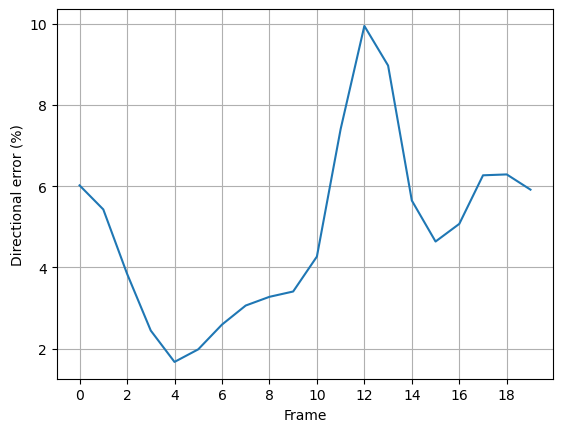

In [ ]:
# plot how the above metrics evolve over time

directional_error_list = []
vectorial_rmse_list = []
rmse_list = []
for i in range(len(masked_velocity)):
    directional_error_list.append(directional_error(masked_target_list[i], masked_target_gt_list[i]))
    vectorial_rmse_list.append(vectorial_rmse(masked_target_list[i], masked_target_gt_list[i]))
    rmse_list.append(rmse(masked_target_list[i], masked_target_gt_list[i]))

plt.plot(directional_error_list, label='Directional error')
plt.xticks(np.arange(0, 20, 2))
plt.xlabel('Frame')
plt.ylabel('Directional error (%)')
plt.grid()
plt.show()

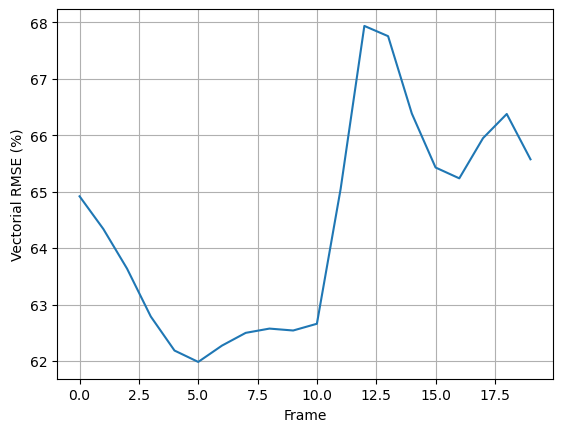

In [ ]:
plt.plot(vectorial_rmse_list, label='Vectorial RMSE')
plt.xlabel('Frame')
plt.ylabel('Vectorial RMSE (%)')
plt.grid()
plt.show()


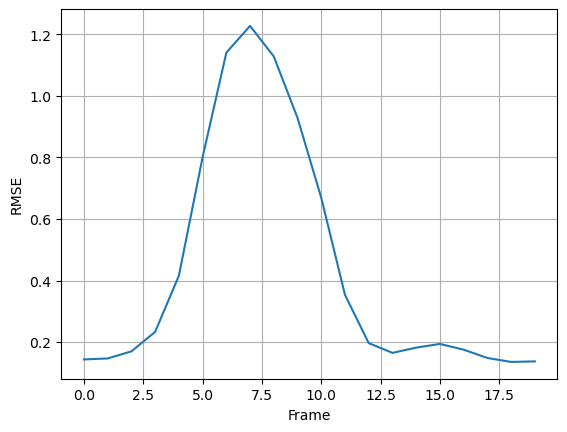

In [ ]:
plt.plot(rmse_list, label='RMSE')
plt.xlabel('Frame')
plt.ylabel('RMSE')
plt.grid()
plt.show()
